# 06 · Avaliação no instante do registro (v2)
**CRISP-DM:** Avaliação · **RQ1, RQ2, RQ3**

Para cada cenário, no instante do registro:
1. **Estado** do período [t − L, t) com L = 15 (principal), 30 e 60 min: Normal ou Residual;
2. **Indicador responsável** (4xx, 5xx, latência ou volume) quando Residual;
3. **Início**: expansão retroativa (0–15, 15–30, 30–60 min, depois de 1 h em 1 h até 4 h) até a primeira faixa Normal;
4. **Abrangência** (complementar): consumidor específico ou generalizado.

Métricas: sensibilidade (incidentes com saída Residual), especificidade (controles com saída Normal), acurácia do indicador, acerto da zona de início, com **IC de Wilson (95%)**; comparação com os baselines pelo **teste de McNemar** (mesmos casos).

In [1]:
%run ./00_funcoes.ipynb

00_funcoes (v2) carregado · /home/wsl/gh/mestrado/claude9/v2


In [2]:
import pickle
import time
with open(RESULTADOS / "04_calibracao.pkl", "rb") as f:
    calib = pickle.load(f)
cenarios = pd.read_csv(RESULTADOS / "05_cenarios.csv", parse_dates=["t_registro"])
brutos = pd.read_parquet(RESULTADOS / "02_brutos_consolidados.parquet")
B = Brutos(brutos)

## Períodos de todos os cenários

In [3]:
t_ini = time.time()
linhas = []
for cen in cenarios.itertuples():
    linhas.extend(periodos_do_cenario(B, cen))
P = pd.DataFrame(linhas)
print(f"{len(P):,} períodos em {time.time() - t_ini:.0f} s")

64,800 períodos em 162 s


## Decisão por método e faixa

In [4]:
dec = {}
for nome in METODOS:
    for L in FAIXAS_L:
        sub = P[(P["periodo"] == "L") & (P["id_periodo"] == L)].set_index("cenario")
        res, ind, vezes = decidir(sub, calib[(nome, L)])
        dec[(nome, L)] = pd.DataFrame({"residual": res, "indicador": ind}, index=sub.index)

# bandas da expansão retroativa (método proposto), cada uma com o limite do seu tamanho
bandas = P[P["periodo"] == "banda"].copy()
bandas["L"] = bandas["hi"] - bandas["lo"]
bandas["residual"] = False
for L in FAIXAS_L:
    m = bandas["L"] == L
    bandas.loc[m, "residual"] = decidir(bandas[m], calib[(PROPOSTO, L)])[0]
res_bandas = bandas.pivot(index="cenario", columns="id_periodo", values="residual")
inicio = pd.DataFrame([estimar_inicio(list(v)) for v in res_bandas.to_numpy()], index=res_bandas.index,
                      columns=["estado_bandas", "zona_lo", "zona_hi"])


def tabela(nome, L):
    t = cenarios.set_index("cenario").join(dec[(nome, L)])
    t["esperado"] = t["motivo"].map(lambda m: MOTIVOS[m][0] if isinstance(m, str) else None)
    t["abr_esperada"] = t["motivo"].map(lambda m: MOTIVOS[m][1] if isinstance(m, str) else None)
    t["acerto_estado"] = np.where(t["tipo"] == "incidente", t["residual"], ~t["residual"])
    return t


T = {(n, L): tabela(n, L) for n in METODOS for L in FAIXAS_L}
inc = lambda t: t[t["tipo"] == "incidente"]
ctl = lambda t: t[t["tipo"] == "controle"]

## RQ1 · Estado no instante do registro

In [5]:
linhas = []
for (n, L), t in T.items():
    i, c = inc(t), ctl(t)
    i_mf = i[i["intensidade"] != "baixa"]
    linhas.append(dict(metodo=n, L=L,
                       sensibilidade=fmt_ic(int(i["residual"].sum()), len(i)),
                       sens_media_alta=fmt_ic(int(i_mf["residual"].sum()), len(i_mf)),
                       especificidade=fmt_ic(int((~c["residual"]).sum()), len(c)),
                       sens=i["residual"].mean(), sens_ma=i_mf["residual"].mean(), espec=(~c["residual"]).mean()))
resumo = pd.DataFrame(linhas)
resumo[["metodo", "L", "sensibilidade", "sens_media_alta", "especificidade"]]

,metodo,L,sensibilidade,sens_media_alta,especificidade
0,Perfil contextual (proposto),15,38.1% [36.6%; 39.7%],44.2% [42.2%; 46.2%],96.8% [96.1%; 97.3%]
1,Perfil contextual (proposto),30,37.1% [35.5%; 38.7%],43.5% [41.6%; 45.5%],97.7% [97.2%; 98.1%]
2,Perfil contextual (proposto),60,34.7% [33.2%; 36.3%],40.7% [38.8%; 42.7%],97.9% [97.3%; 98.3%]
3,z-score global,15,36.2% [34.7%; 37.8%],41.8% [39.8%; 43.7%],97.4% [96.9%; 97.9%]
4,z-score global,30,34.4% [32.9%; 36.0%],39.8% [37.9%; 41.8%],98.6% [98.2%; 99.0%]
5,z-score global,60,32.3% [30.8%; 33.9%],37.7% [35.7%; 39.6%],98.2% [97.8%; 98.6%]
6,Semana anterior,15,36.9% [35.4%; 38.5%],41.9% [39.9%; 43.9%],97.4% [96.9%; 97.9%]
7,Semana anterior,30,35.8% [34.3%; 37.4%],41.5% [39.5%; 43.4%],97.6% [97.1%; 98.1%]
8,Semana anterior,60,33.9% [32.4%; 35.5%],39.8% [37.9%; 41.8%],98.2% [97.7%; 98.6%]


### Comparação com os baselines (McNemar, mesmos casos)

In [6]:
mc = []
for L in FAIXAS_L:
    a = T[(PROPOSTO, L)]["acerto_estado"]
    for b in METODOS:
        if b == PROPOSTO:
            continue
        n01, n10, p = mcnemar(a, T[(b, L)].loc[a.index, "acerto_estado"])
        mc.append(dict(L=L, baseline=b, so_proposto_acerta=n01, so_baseline_acerta=n10, p=p))
mc = pd.DataFrame(mc)
mc

,L,baseline,so_proposto_acerta,so_baseline_acerta,p
0,15,z-score global,180,136,0.015433
1,15,Semana anterior,193,174,0.347440
2,30,z-score global,181,117,0.000250
3,30,Semana anterior,196,147,0.009449
4,60,z-score global,200,127,0.000064
5,60,Semana anterior,176,159,0.382052


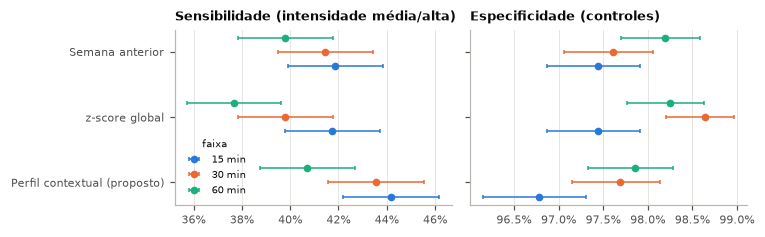

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.2), sharey=True)
metodos = list(METODOS)
for ax, (col, titulo) in zip(axes, [("sens_ma", "Sensibilidade (intensidade média/alta)"), ("espec", "Especificidade (controles)")]):
    for j, L in enumerate(FAIXAS_L):
        for i, n in enumerate(metodos):
            t = T[(n, L)]
            base = inc(t)[inc(t)["intensidade"] != "baixa"] if col == "sens_ma" else ctl(t)
            k = int(base["residual"].sum()) if col == "sens_ma" else int((~base["residual"]).sum())
            p = k / len(base)
            lo, hi = wilson(k, len(base))
            y = i + (j - 1) * 0.22
            ax.errorbar(p, y, xerr=[[p - lo], [hi - p]], fmt="o", ms=4, color=CORES[j], ecolor=CORES[j], lw=1,
                        capsize=1.5, label=f"{L} min" if i == 0 else None)
    ax.set_yticks(range(len(metodos)))
    ax.set_yticklabels(metodos)
    ax.invert_yaxis()
    ax.set_title(titulo, loc="left")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0 if col == "sens_ma" else 1))
    ax.grid(axis="y", visible=False)
axes[0].legend(title="faixa", loc="lower left", fontsize=6.5, title_fontsize=6.5)
fig.tight_layout()
salvar(fig, "fig_metodos")
plt.show()

### Sensibilidade por motivo e intensidade (método proposto, 15 min)

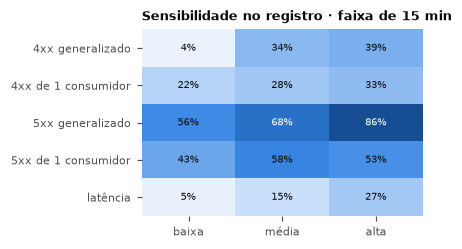

,baixa,média,alta
motivo,,,
4xx generalizado,0.042,0.342,0.388
4xx de 1 consumidor,0.217,0.279,0.329
5xx generalizado,0.558,0.683,0.862
5xx de 1 consumidor,0.433,0.583,0.529
latência,0.054,0.154,0.267


In [8]:
t15 = inc(T[(PROPOSTO, L_PRINCIPAL)])
sm = t15.groupby(["motivo", "intensidade"])["residual"].mean().unstack()[INTENSIDADES]
sm.index = sm.index.map(NOMES_MOTIVO)
sm = sm.loc[[NOMES_MOTIVO[m] for m in MOTIVOS]]
sm.columns = ["baixa", "média", "alta"]
fig, ax = plt.subplots(figsize=(3.3, 2.2))
heatmap(ax, sm)
ax.set_title("Sensibilidade no registro · faixa de 15 min", loc="left")
salvar(fig, "fig_sens_motivo")
plt.show()
sm.round(3)

## Ponto de operação: 1%, 2% e 5% de alarmes em agosto
Mesmos limites-base (percentil 99 por indicador), variando o multiplicador c. A meta adotada é 5% (c = 1).

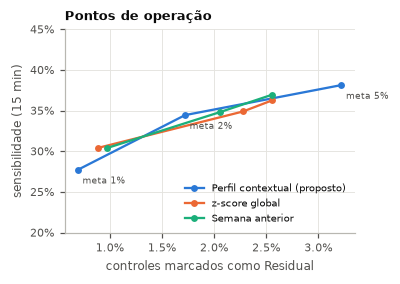

,metodo,meta,c,alarmes_agosto,sensibilidade,sens_media_alta,especificidade,sens_latencia,acuracia_indicador
0,Perfil contextual (proposto),0.01,1.73,0.010,0.277,0.340,0.993,0.040,0.991
1,Perfil contextual (proposto),0.02,1.22,0.020,0.344,0.401,0.983,0.099,0.981
2,Perfil contextual (proposto),0.05,1.00,0.035,0.381,0.442,0.968,0.158,0.964
3,z-score global,0.01,1.33,0.010,0.304,0.352,0.991,0.068,0.984
4,z-score global,0.02,1.08,0.020,0.349,0.403,0.977,0.139,0.965
5,z-score global,0.05,1.00,0.030,0.362,0.418,0.974,0.164,0.959
6,Semana anterior,0.01,1.42,0.010,0.304,0.356,0.990,0.043,0.984
7,Semana anterior,0.02,1.11,0.020,0.348,0.397,0.979,0.099,0.970
8,Semana anterior,0.05,1.00,0.034,0.369,0.419,0.974,0.133,0.966


In [9]:
p15 = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario").join(cenarios.set_index("cenario")[["tipo", "motivo", "intensidade"]])
curva = []
for nome in METODOS:
    cal = calib[(nome, L_PRINCIPAL)]
    razao = (z_direcional(cal["modelo"].z(p15)) / cal["base"].reindex(p15["recurso"]).to_numpy())
    mx = razao.max(axis=1)
    for meta in METAS_CURVA:
        c = max(1.0, float(np.quantile(cal["razao_cal"], 1 - meta)))
        res = mx > c
        inc_ = p15["tipo"] == "incidente"
        ind = razao[res & inc_].idxmax(axis=1).map(INDICADOR)
        esp = p15.loc[res & inc_, "motivo"].map(lambda m: MOTIVOS[m][0])
        curva.append(dict(metodo=nome, meta=meta, c=round(c, 2), alarmes_agosto=float((cal["razao_cal"] > c).mean()),
                          sensibilidade=res[inc_].mean(), sens_media_alta=res[inc_ & (p15["intensidade"] != "baixa")].mean(),
                          especificidade=(~res[~inc_]).mean(), sens_latencia=res[inc_ & (p15["motivo"] == "latencia")].mean(),
                          acuracia_indicador=(ind == esp).mean()))
curva = pd.DataFrame(curva)
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for i, nome in enumerate(METODOS):
    c_ = curva[curva["metodo"] == nome]
    ax.plot(1 - c_["especificidade"], c_["sensibilidade"], marker="o", ms=3.5, color=CORES[i], label=nome)
    for _, r_ in c_.iterrows():
        if nome == PROPOSTO:
            ax.annotate(f"meta {r_['meta']:.0%}", (1 - r_["especificidade"], r_["sensibilidade"]), fontsize=6,
                        xytext=(3, -9), textcoords="offset points", color=TXT2)
ax.set_xlabel("controles marcados como Residual")
ax.set_ylabel("sensibilidade (15 min)")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1))
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.set_ylim(0.2, 0.45)
ax.legend(loc="lower right", fontsize=6.3)
ax.set_title("Pontos de operação", loc="left")
salvar(fig, "fig_curva_operacao")
plt.show()
curva.round(3)

## RQ3 · Tamanho da faixa × atraso do registro

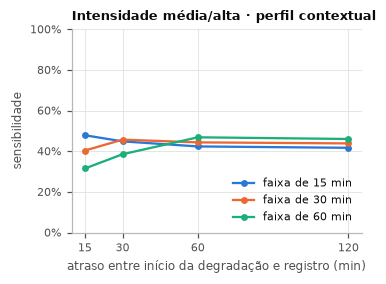

,15,30,60
atraso,,,
15.0,0.410,0.323,0.243
30.0,0.390,0.399,0.317
60.0,0.369,0.383,0.416
120.0,0.357,0.379,0.413


,15,30,60
atraso,,,
15.0,0.478,0.403,0.315
30.0,0.448,0.457,0.385
60.0,0.423,0.443,0.468
120.0,0.417,0.438,0.460


In [10]:
sa = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).groupby("atraso")["residual"].mean() for L in FAIXAS_L})
sa_ma = pd.DataFrame({L: inc(T[(PROPOSTO, L)]).query("intensidade != 'baixa'").groupby("atraso")["residual"].mean()
                      for L in FAIXAS_L})
fig, ax = plt.subplots(figsize=(3.4, 2.4))
for j, L in enumerate(FAIXAS_L):
    ax.plot(sa_ma.index, sa_ma[L], marker="o", ms=3.5, color=CORES[j], label=f"faixa de {L} min")
ax.set_xticks(ATRASOS)
ax.set_xlabel("atraso entre início da degradação e registro (min)")
ax.set_ylabel("sensibilidade")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.legend(loc="lower right")
ax.set_title("Intensidade média/alta · perfil contextual", loc="left")
salvar(fig, "fig_sens_atraso")
plt.show()
display(sa.round(3))
sa_ma.round(3)

## RQ2 · Indicador responsável (método proposto)

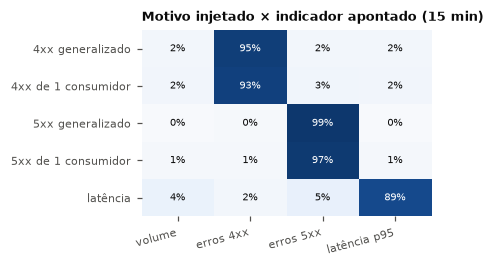

indicador,volume,erros 4xx,erros 5xx,latência p95
motivo,,,,
4xx generalizado,0.016,0.951,0.016,0.016
4xx de 1 consumidor,0.020,0.934,0.025,0.020
5xx generalizado,0.002,0.004,0.992,0.002
5xx de 1 consumidor,0.008,0.011,0.973,0.008
latência,0.044,0.018,0.053,0.886


15    96.4% [95.3%; 97.3%]
30    97.2% [96.2%; 98.0%]
60    97.0% [95.9%; 97.8%]
Name: acurácia do indicador, dtype: str

In [11]:
det15 = t15[t15["residual"]]
conf = pd.crosstab(det15["motivo"].map(NOMES_MOTIVO), det15["indicador"], normalize="index")
conf = conf.reindex(index=[NOMES_MOTIVO[m] for m in MOTIVOS], columns=list(INDICADOR.values()), fill_value=0)
acc_ind = {L: (inc(T[(PROPOSTO, L)]).query("residual")["indicador"] == inc(T[(PROPOSTO, L)]).query("residual")["esperado"]) for L in FAIXAS_L}
acc_ind_tab = pd.Series({L: fmt_ic(int(v.sum()), len(v)) for L, v in acc_ind.items()}, name="acurácia do indicador")
fig, ax = plt.subplots(figsize=(3.4, 2.2))
heatmap(ax, conf)
ax.set_xticklabels(conf.columns, rotation=15, ha="right")
ax.set_title("Motivo injetado × indicador apontado (15 min)", loc="left")
salvar(fig, "fig_confusao_indicador")
plt.show()
display(conf.round(3))
acc_ind_tab

### Abrangência (complementar)

In [12]:
Pidx = P[(P["periodo"] == "L") & (P["id_periodo"] == L_PRINCIPAL)].set_index("cenario")
d_ok = det15[det15["indicador"] == det15["esperado"]]
d_ok = d_ok[d_ok["motivo"].str.startswith(("4xx", "5xx"))]
abr = pd.Series({c: abrangencia(Pidx.loc[c], d_ok.loc[c, "indicador"]) for c in d_ok.index})
d_ok = d_ok.assign(abr_prevista=abr)
tab_abr = pd.crosstab(d_ok["motivo"].map(NOMES_MOTIVO), d_ok["abr_prevista"], normalize="index").round(2)
acc_abr = (d_ok["abr_prevista"] == d_ok["abr_esperada"])
display(tab_abr)
print("acurácia da abrangência:", fmt_ic(int(acc_abr.sum()), len(acc_abr)))

abr_prevista,consumidor específico,generalizado,indeterminada
motivo,,,
4xx de 1 consumidor,0.60,0.34,0.06
4xx generalizado,0.02,0.94,0.05
5xx de 1 consumidor,0.69,0.22,0.09
5xx generalizado,0.04,0.91,0.05


acurácia da abrangência: 80.4% [78.1%; 82.5%]


## RQ2 · Início estimado (expansão retroativa, método proposto)
Zona estimada: entre o início da última faixa residual e o fim da primeira faixa normal (em minutos antes do registro). Acerto: o início real está dentro da zona.

In [13]:
ti = inc(T[(PROPOSTO, L_PRINCIPAL)]).join(inicio)
ti = ti[ti["estado_bandas"] == "Residual"]
ti["acerto_inicio"] = (ti["atraso"] >= ti["zona_lo"]) & (ti["zona_hi"].isna() | (ti["atraso"] <= ti["zona_hi"]))
acerto_inicio = ti.groupby("atraso")["acerto_inicio"].agg(["mean", "size"])
acerto_inicio["IC 95%"] = [fmt_ic(int(round(m * n)), n) for m, n in acerto_inicio.to_numpy()]
print("acerto geral da zona de início:", fmt_ic(int(ti["acerto_inicio"].sum()), len(ti)))
zonas = ti.assign(zona=ti["zona_lo"].astype(int).astype(str) + "–" + ti["zona_hi"].fillna(-1).astype(int).astype(str).replace("-1", "mais")
                  ).groupby(["atraso", "zona"]).size().unstack(fill_value=0)
display(acerto_inicio)
zonas

acerto geral da zona de início: 92.9% [91.4%; 94.1%]


,mean,size,IC 95%
atraso,,,
15.0,0.991870,369,99.2% [97.6%; 99.7%]
30.0,1.000000,351,100.0% [98.9%; 100.0%]
60.0,0.882530,332,88.3% [84.3%; 91.3%]
120.0,0.825545,321,82.6% [78.0%; 86.3%]


zona,0–30,120–240,15–60,180–mais,30–120,60–180
atraso,,,,,,
15.0,356,0,10,0,1,2
30.0,53,0,290,0,8,0
60.0,38,1,16,0,271,6
120.0,36,3,19,1,20,242


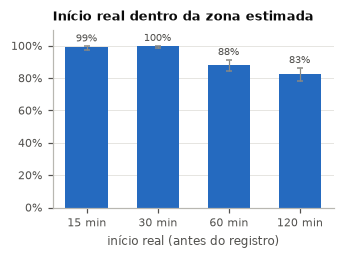

In [14]:
fig, ax = plt.subplots(figsize=(3.3, 2.1))
ax.bar(range(len(ATRASOS)), acerto_inicio["mean"], color=AZUL[4], width=0.6)
for i, (m, n) in enumerate(acerto_inicio[["mean", "size"]].to_numpy()):
    lo, hi = wilson(int(round(m * n)), n)
    ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], color=TXT3, capsize=2, lw=0.8)
    ax.text(i, hi + 0.03, f"{m:.0%}", ha="center", fontsize=6.8, color=TXT2)
ax.set_xticks(range(len(ATRASOS)))
ax.set_xticklabels([f"{a} min" for a in ATRASOS])
ax.set_xlabel("início real (antes do registro)")
ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=0))
ax.set_title("Início real dentro da zona estimada", loc="left")
ax.grid(axis="x", visible=False)
salvar(fig, "fig_inicio")
plt.show()

### Exemplo de expansão retroativa

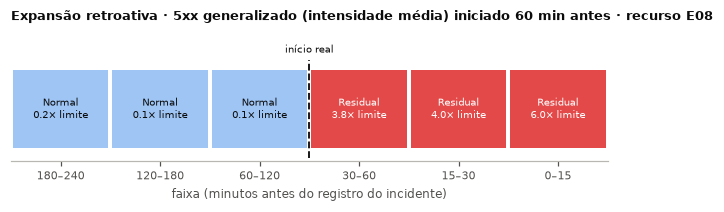

In [15]:
cand = ti[(ti["motivo"] == "5xx_geral") & (ti["atraso"] == 60) & ti["acerto_inicio"] & (ti["intensidade"] == "media")]
if cand.empty:
    cand = ti[ti["acerto_inicio"] & (ti["atraso"] >= 30)]
c_ex = cand.index[0]
b_ex = bandas[bandas["cenario"] == c_ex].sort_values("id_periodo")
cal_by_L = {L: calib[(PROPOSTO, L)] for L in FAIXAS_L}
vezes_ex = [decidir(b_ex[b_ex["id_periodo"] == i], cal_by_L[int(b_ex.loc[b_ex["id_periodo"] == i, "L"].iloc[0])])[2].max(axis=1).iloc[0]
            for i in b_ex["id_periodo"]]
fig, ax = plt.subplots(figsize=(7.0, 1.55))
nb = len(BANDAS)
atraso_ex = int(cenarios.set_index("cenario").loc[c_ex, "atraso"])
for k, ((lo, hi), res_b, v) in enumerate(zip(BANDAS, b_ex["residual"], vezes_ex)):
    x = nb - 1 - k  # mais antiga à esquerda, registro à direita
    ax.barh(0, 0.96, left=x + 0.02, height=0.6, color=CORES[7] if res_b else AZUL[1])
    ax.text(x + 0.5, 0, f"{'Residual' if res_b else 'Normal'}\n{v:.1f}× limite", ha="center", va="center", fontsize=6.5,
            color="white" if res_b else TXT1)
    if lo < atraso_ex <= hi:  # posição do início real dentro da faixa
        xr = x + 1 - (atraso_ex - lo) / (hi - lo)
        ax.plot([xr, xr], [-0.38, 0.38], color=TXT1, lw=1.2, ls="--")
        ax.text(xr, 0.42, "início real", fontsize=6.5, ha="center", va="bottom")
ax.set_xlim(0, nb)
ax.set_ylim(-0.4, 0.62)
ax.set_xticks([nb - 0.5 - k for k in range(nb)])
ax.set_xticklabels([f"{lo}–{hi}" for lo, hi in BANDAS])
ax.set_xlabel("faixa (minutos antes do registro do incidente)")
ax.set_yticks([])
ax.grid(False)
ax.spines["left"].set_visible(False)
ax.set_title(f"Expansão retroativa · 5xx generalizado (intensidade média) iniciado {atraso_ex} min antes · recurso "
             f"{rot(cenarios.set_index('cenario').loc[c_ex, 'recurso'])}", loc="left")
salvar(fig, "fig_expansao_exemplo")
plt.show()

## Por recurso (método proposto, 15 min)

In [16]:
por_rec = pd.DataFrame({
    "sensibilidade": inc(T[(PROPOSTO, 15)]).groupby("recurso")["residual"].mean(),
    "sens. média/alta": inc(T[(PROPOSTO, 15)]).query("intensidade != 'baixa'").groupby("recurso")["residual"].mean(),
    "especificidade": (~ctl(T[(PROPOSTO, 15)])["residual"]).groupby(ctl(T[(PROPOSTO, 15)])["recurso"]).mean(),
    "acurácia indicador": det15.assign(ok=det15["indicador"] == det15["esperado"]).groupby("recurso")["ok"].mean(),
})
por_rec.index = por_rec.index.map(rot)
por_rec = por_rec.sort_index()
por_rec.round(2)

,sensibilidade,sens. média/alta,especificidade,acurácia indicador
recurso,,,,
E01,0.75,0.85,0.96,0.98
E02,0.17,0.22,0.98,0.94
E03,0.29,0.34,0.95,0.86
E04,0.38,0.40,0.97,0.98
E05,0.66,0.74,0.98,0.99
E06,0.14,0.16,0.94,0.74
E07,0.42,0.48,0.98,0.98
E08,0.50,0.56,0.96,0.97
E09,0.68,0.78,0.96,0.99


## Critérios de sucesso

In [17]:
r15 = resumo[(resumo["metodo"] == PROPOSTO) & (resumo["L"] == 15)].iloc[0]
acc15 = acc_ind[15]
p_min = mc[(mc["L"] == 15)]
perde = ((p_min["so_baseline_acerta"] > p_min["so_proposto_acerta"]) & (p_min["p"] < 0.05)).any()
criterios = pd.DataFrame([
    ("Controles com saída Normal ≥ 95%", f"{r15['espec']:.1%}", r15["espec"] >= 0.95),
    ("Sensibilidade 15 min, intensidade média/alta ≥ 70%", f"{r15['sens_ma']:.1%}", r15["sens_ma"] >= 0.70),
    ("Acurácia do indicador ≥ 90%", f"{acc15.mean():.1%}", acc15.mean() >= 0.90),
    ("Início real na zona estimada ≥ 70%", f"{ti['acerto_inicio'].mean():.1%}", ti["acerto_inicio"].mean() >= 0.70),
    ("Sem perda significativa para baselines (McNemar)", "sim" if not perde else "não", not perde),
], columns=["critério", "resultado", "atendido"])
criterios

,critério,resultado,atendido
0,Controles com saída Normal ≥ 95%,96.8%,True
1,"Sensibilidade 15 min, intensidade média/alta ≥...",44.2%,False
2,Acurácia do indicador ≥ 90%,96.4%,True
3,Início real na zona estimada ≥ 70%,92.9%,True
4,Sem perda significativa para baselines (McNemar),sim,True


In [18]:
P.to_parquet(RESULTADOS / "06_periodos.parquet", index=False)
pd.concat({f"{n} | {L}": t for (n, L), t in T.items()}).to_parquet(RESULTADOS / "06_decisoes.parquet")
resumo.to_csv(RESULTADOS / "06_resumo.csv", index=False)
mc.to_csv(RESULTADOS / "06_mcnemar.csv", index=False)
sm.to_csv(RESULTADOS / "06_sens_motivo.csv")
sa.to_csv(RESULTADOS / "06_sens_atraso.csv")
sa_ma.to_csv(RESULTADOS / "06_sens_atraso_media_alta.csv")
conf.to_csv(RESULTADOS / "06_confusao_indicador.csv")
acc_ind_tab.to_csv(RESULTADOS / "06_acuracia_indicador.csv")
tab_abr.to_csv(RESULTADOS / "06_abrangencia.csv")
acerto_inicio.to_csv(RESULTADOS / "06_inicio.csv")
zonas.to_csv(RESULTADOS / "06_zonas_inicio.csv")
por_rec.to_csv(RESULTADOS / "06_por_recurso.csv")
criterios.to_csv(RESULTADOS / "06_criterios.csv", index=False)
curva.to_csv(RESULTADOS / "06_curva_operacao.csv", index=False)
salvar_json(dict(acuracia_abrangencia=float(acc_abr.mean()), n_abrangencia=int(len(acc_abr)),
                 acerto_inicio=float(ti["acerto_inicio"].mean()), n_inicio=int(len(ti)),
                 cenario_exemplo=int(c_ex)), "06_resumo.json")
print("resultados salvos")

resultados salvos
